# Clasificación de textos en Esperanto
**Práctica de Minería de Textos · 4º INF-A · 2026/2027 — Punto de control (Fases 1 y 2)**

**Equipo:** Mikel Echarri Richard · Joaquín Álvarez Julia · Víctor Hernández Enciso

---

## Contenido
1. Configuración
2. **Fase 1 — Dataset**: categorías, descarga desde Wikipedia, limpieza, medida del ruido y CSV
3. **Fase 2 — Modelo de NLP para Esperanto**: tokenizador, POS, lematizador, stop-words y API tipo spaCy
4. Primer análisis del corpus con nuestro modelo
5. Pendiente para la entrega final (Fase 3)

**Cómo ejecutarlo:** `Entorno de ejecución → Ejecutar todo`. El cuaderno es autocontenido: no usa ficheros locales y solo necesita
acceso a Internet para Wikipedia y para la lista de stop-words (si alguna de las dos webs falla, hay un plan B).

## 1. Configuración
Todos los parámetros que se pueden tocar están en esta celda. Las semillas están fijadas para que el resultado sea reproducible.

In [1]:
import re
import time
import random
import unicodedata
from collections import Counter
from concurrent.futures import ThreadPoolExecutor

import requests
import pandas as pd
import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:          # fuera de Jupyter
    display = print

SEMILLA = 42
random.seed(SEMILLA)

# --- Parámetros de la Fase 1 (dataset) ---
GENERAR_DATASET = True          # True: se descarga de Wikipedia. False: se lee el CSV ya publicado en GitHub.
DATASET_URL_BASE = ""           # URL "raw" de la carpeta de GitHub donde están los CSV (se rellena al subirlos).
ARCHIVO_DATASET = "dataset.csv"                         # contrato de datos: columnas text;class
ARCHIVO_DATASET_ARTICULOS = "dataset_con_articulos.csv" # igual + columna article (para particionar por artículo en la Fase 3)

MAX_ARTICULOS_POR_CLASE = 250   # artículos que se descargan como máximo por clase
MAX_PARRAFOS_POR_CLASE = 600    # tamaño final (equilibrado) por clase
LONGITUD_MIN_PARRAFO = 100      # caracteres
PALABRAS_MIN_PARRAFO = 15       # palabras

## 2. Fase 1 — Dataset

### 2.1 Decisiones de diseño

**Categorías elegidas: `fiziko` (física), `kemio` (química) y `biologio` (biología).**
* Son ciencias naturales cercanas entre sí, así que la clasificación **no es trivial**: comparten mucho vocabulario
  (energía, moléculas, átomos, células...). Es lo que pide el enunciado.
* La Wikipedia en Esperanto tiene en estas categorías artículos largos, con párrafos de verdad
  (en otras, como animales, hay muchos artículos de una sola frase).
* Comprobamos con el API de Wikipedia que hay material suficiente: `Fiziko` (256 artículos directos), `Kemio` (153) y `Biologio` (116 + 65 subcategorías).

**Fuente:** API de Wikipedia en Esperanto (`eo.wikipedia.org`). Pedimos el texto plano de cada artículo y lo dividimos en párrafos.

**Cómo se eligen los artículos:** los de la categoría y los de sus subcategorías (un nivel). Excluimos subcategorías que no son
de contenido (listas, biografías, organizaciones, esbozos) o que se solapan con otra clase (`Biokemio`, `Biofiziko`, `Kvantuma kemio`).
Si un artículo sale en dos clases, se **elimina** (es ambiguo).

**Limpieza (contrato de datos):** CSV UTF-8, separador `;`, columnas `text;class`, un párrafo por fila, sin HTML, links ni referencias `[1]`,
y sin el carácter `;` en el texto. Secciones como *Referencoj* o *Eksteraj ligiloj* se descartan.

**Ruido:** heredamos la etiqueta del artículo, así que hay párrafos genéricos que no distinguen la clase
(p. ej. «Ĝi estis fondita en 1950»). Más abajo medimos el ruido de forma aproximada y revisamos una muestra a mano.

In [2]:
API = "https://eo.wikipedia.org/w/api.php"
CONTACTO = "https://www.cunef.edu"   # Wikipedia pide identificarse en el User-Agent (web o correo de contacto)
sesion = requests.Session()
sesion.headers.update({"User-Agent": f"CUNEF-MineriaTextos-Practica/1.0 ({CONTACTO}; trabajo academico)"})

# Wikipedia limita las peticiones (error HTTP 429) si se hacen muchas y muy rápido, sobre todo desde Colab.
# Por eso descargamos con pocos hilos, con pausas y reintentos que respetan la cabecera Retry-After.
NUM_HILOS = 2
PAUSA_ENTRE_PETICIONES = 0.3   # segundos
ERRORES = Counter()            # recuento de fallos por tipo, para saber por qué falla una descarga

# Etiqueta de cada clase -> categorías de Wikipedia de partida. Se añaden también las subcategorías (un nivel).
# Si alguna categoría no existe, simplemente no devuelve artículos (se avisa por pantalla).
CATEGORIAS = {
    "fiziko":   ["Fiziko"],
    "kemio":    ["Kemio", "Konceptoj en kemio", "Kemiaj elementoj", "Organika kemio", "Neorganika kemio", "Analiza kemio"],
    "biologio": ["Biologio"],
}

# Si el nombre de una subcategoría contiene alguno de estos trozos, no se usa.
SUBCATS_EXCLUIDAS = [
    "biograf", "listoj", "asocioj", "organizaĵoj", "datumbazoj", "rekordoj", "artikoloj", "ĝermoj", "literaturo",
    "historio", "filozofio", "en fikcio", "premioj", "studfakoj", "kaj kulturo", "ŝablono", "magio",
    "biologoj", "fizikistoj", "kemiistoj",                      # personas
    "biokemio", "biofiziko", "kvantuma kemio", "astrobiologio",  # se solapan con otra clase
    "faŭno", "flaŭro", "endemiismoj", "vivaĵoj",                 # listas de especies por región
]

# Secciones que no son prosa (listas de enlaces, referencias...)
SECCIONES_EXCLUIDAS = {"referencoj", "eksteraj ligiloj", "vidu ankaŭ", "notoj", "literaturo", "bibliografio",
                       "fontoj", "ligiloj", "legu ankaŭ"}


def pedir(parametros, intentos=6):
    """Hace una petición al API de Wikipedia. Si Wikipedia dice 'demasiadas peticiones' (429/503) espera lo que
    pide en Retry-After y reintenta; devuelve None si no hay manera."""
    for intento in range(intentos):
        try:
            respuesta = sesion.get(API, params={**parametros, "format": "json", "formatversion": 2}, timeout=30)
            if respuesta.status_code in (429, 503):
                ERRORES[f"HTTP {respuesta.status_code}"] += 1
                try:
                    espera = float(respuesta.headers.get("Retry-After", 2 ** (intento + 1)))
                except ValueError:
                    espera = 2 ** (intento + 1)
                time.sleep(min(espera, 30))
                continue
            respuesta.raise_for_status()
            return respuesta.json()
        except (requests.RequestException, ValueError) as error:
            ERRORES[type(error).__name__] += 1
            time.sleep(2 ** intento)
    return None


def miembros_de_categoria(categoria, tipo):
    """Títulos de los artículos (tipo='page') o de las subcategorías (tipo='subcat') de una categoría.
    El API devuelve los resultados por tandas; seguimos pidiendo mientras haya 'continue'."""
    titulos, continuar = [], None
    while True:
        parametros = {"action": "query", "list": "categorymembers", "cmtitle": f"Kategorio:{categoria}",
                      "cmtype": tipo, "cmlimit": 500}
        if tipo == "page":
            parametros["cmnamespace"] = 0          # solo artículos (no plantillas, ni páginas de ayuda)
        if continuar:
            parametros["cmcontinue"] = continuar
        datos = pedir(parametros)
        if datos is None:
            print(f"   · no se pudo leer la categoría '{categoria}' ({tipo}); Wikipedia no responde o nos limita")
            break
        if "error" in datos:       # la categoría no existe
            break
        titulos += [m["title"] for m in datos.get("query", {}).get("categorymembers", [])]
        continuar = datos.get("continue", {}).get("cmcontinue")
        if not continuar:
            break
    return titulos


def articulos_de_clase(semillas):
    """Conjunto de artículos de una clase: los de cada categoría semilla y los de sus subcategorías útiles."""
    articulos = set()
    for categoria in semillas:
        articulos.update(miembros_de_categoria(categoria, "page"))
        for sub in miembros_de_categoria(categoria, "subcat"):
            nombre = sub.replace("Kategorio:", "")
            if any(malo in nombre.lower() for malo in SUBCATS_EXCLUIDAS):
                continue
            articulos.update(miembros_de_categoria(nombre, "page"))
    return articulos


def texto_de_articulo(titulo):
    """Texto plano de un artículo (sin marcado wiki). Devuelve '' si falla.
    (El API solo da el texto completo de un artículo por petición, así que no se puede agrupar.)"""
    time.sleep(PAUSA_ENTRE_PETICIONES)
    datos = pedir({"action": "query", "prop": "extracts", "explaintext": 1, "redirects": 1, "titles": titulo})
    if datos is None:
        ERRORES["petición fallida"] += 1
        return ""
    paginas = datos.get("query", {}).get("pages", [])
    texto = (paginas[0].get("extract") or "") if paginas else ""
    if not texto:
        ERRORES["artículo sin texto"] += 1
    return texto


def limpiar_parrafo(parrafo):
    """Quita referencias [1], enlaces, paréntesis vacíos y el carácter ';' (prohibido en el CSV)."""
    parrafo = re.sub(r"\[[^\]]*\]", "", parrafo)               # [1]  [citaĵo bezonata]
    parrafo = re.sub(r"https?://\S+|www\.\S+", "", parrafo)    # enlaces
    parrafo = re.sub(r"\(\s*\)", "", parrafo)                  # paréntesis que se quedan vacíos
    parrafo = parrafo.replace(";", ",")
    return re.sub(r"\s+", " ", parrafo).strip()


def es_parrafo_valido(parrafo):
    """Descarta títulos, listas y fragmentos: exige longitud mínima, frase terminada y mayoría de letras."""
    if len(parrafo) < LONGITUD_MIN_PARRAFO or len(parrafo.split()) < PALABRAS_MIN_PARRAFO:
        return False
    if parrafo[-1] not in ".!?»”\")":
        return False
    return sum(c.isalpha() for c in parrafo) / len(parrafo) >= 0.7


def parrafos_de_texto(texto):
    """Divide el texto de un artículo en párrafos limpios, saltando secciones que no son prosa."""
    resultado, seccion = [], ""
    for linea in texto.split("\n"):
        linea = linea.strip()
        if not linea:
            continue
        encabezado = re.fullmatch(r"=+\s*(.*?)\s*=+", linea)     # "== Historio =="
        if encabezado:
            seccion = encabezado.group(1).lower()
            continue
        if seccion in SECCIONES_EXCLUIDAS:
            continue
        parrafo = limpiar_parrafo(linea)
        if es_parrafo_valido(parrafo):
            resultado.append(parrafo)
    return resultado


def descargar_clase(etiqueta, titulos):
    """Descarga (en paralelo) los artículos de una clase y devuelve una fila por párrafo."""
    with ThreadPoolExecutor(max_workers=NUM_HILOS) as pool:
        textos = list(pool.map(texto_de_articulo, titulos))
    fallidos = sum(1 for t in textos if not t)
    if fallidos:
        print(f"   · {fallidos} artículos de '{etiqueta}' no se pudieron descargar (se ignoran). Fallos: {dict(ERRORES)}")
    filas = []
    for titulo, texto in zip(titulos, textos):
        for parrafo in parrafos_de_texto(texto):
            filas.append({"text": parrafo, "class": etiqueta, "article": titulo})
    return filas


def generar_dataset():
    """Construye el dataset completo desde Wikipedia. Devuelve un DataFrame con text, class y article."""
    random.seed(SEMILLA)
    articulos_por_clase = {}
    for etiqueta, semillas in CATEGORIAS.items():
        articulos = sorted(articulos_de_clase(semillas))   # sorted: orden estable entre ejecuciones
        if not articulos:                                  # lo más probable: Wikipedia nos está limitando
            print(f"{etiqueta}: 0 artículos. Fallos: {dict(ERRORES)}. Espero 60 s y reintento...")
            time.sleep(60)
            articulos = sorted(articulos_de_clase(semillas))
        print(f"{etiqueta}: {len(articulos)} artículos candidatos")
        if not articulos:
            raise RuntimeError(f"No se obtuvo ningún artículo de '{etiqueta}'. Fallos: {dict(ERRORES)}")
        articulos_por_clase[etiqueta] = articulos

    # Un artículo que aparece en dos clases es ambiguo: se elimina de todas.
    conteo = Counter(t for lista in articulos_por_clase.values() for t in lista)
    ambiguos = {t for t, n in conteo.items() if n > 1}
    print(f"Artículos ambiguos (en más de una clase), eliminados: {len(ambiguos)}")

    filas = []
    for etiqueta, lista in articulos_por_clase.items():
        lista = [t for t in lista if t not in ambiguos]
        random.shuffle(lista)
        lista = lista[:MAX_ARTICULOS_POR_CLASE]
        print(f"Descargando {len(lista)} artículos de '{etiqueta}'...")
        filas += descargar_clase(etiqueta, lista)

    if not filas:
        raise RuntimeError("No se ha podido descargar nada de Wikipedia. Revisa la conexión o usa GENERAR_DATASET = False.")
    return pd.DataFrame(filas).drop_duplicates(subset="text").reset_index(drop=True)


def cargar_dataset_publicado():
    """Lee el CSV ya generado y publicado en GitHub. Si falla, lo genera desde Wikipedia."""
    try:
        df = pd.read_csv(DATASET_URL_BASE + ARCHIVO_DATASET_ARTICULOS, sep=";", encoding="utf-8")
        print(f"Dataset leído de GitHub: {len(df)} párrafos")
        return df
    except Exception as error:          # sin URL, sin conexión, fichero inexistente...
        print(f"No se pudo leer el dataset publicado ({type(error).__name__}). Se genera desde Wikipedia.")
        return generar_dataset()


def equilibrar(df, maximo):
    """Mismo número de párrafos por clase (el de la clase más pequeña, con un tope), con muestreo reproducible."""
    n = min(maximo, df["class"].value_counts().min())
    partes = [grupo.sample(n=n, random_state=SEMILLA) for _, grupo in df.groupby("class")]
    return pd.concat(partes).sample(frac=1, random_state=SEMILLA).reset_index(drop=True)

### 2.2 Generar (o cargar) el dataset
Con `GENERAR_DATASET = True` se descarga de Wikipedia (unos minutos). Con `False` se lee el CSV ya publicado en GitHub
(el código de generación sigue estando en el cuaderno, solo se desactiva).

In [3]:
df_completo = generar_dataset() if GENERAR_DATASET else cargar_dataset_publicado()
print(f"\nPárrafos válidos antes de equilibrar:\n{df_completo['class'].value_counts().to_string()}")

fiziko: 488 artículos candidatos
kemio: 672 artículos candidatos
biologio: 1495 artículos candidatos
Artículos ambiguos (en más de una clase), eliminados: 53
Descargando 250 artículos de 'fiziko'...
Descargando 250 artículos de 'kemio'...
   · 1 artículos de 'kemio' no se pudieron descargar (se ignoran). Fallos: {'HTTP 429': 5, 'artículo sin texto': 1}
Descargando 250 artículos de 'biologio'...

Párrafos válidos antes de equilibrar:
class
fiziko      1658
kemio       1200
biologio    1103


### 2.3 Medir el ruido
Como cada párrafo hereda la etiqueta de su artículo, algunos no dicen nada de la categoría. No podemos medirlo exactamente
sin etiquetar a mano, así que usamos **indicadores aproximados**:
* párrafos **cortos** (poca información),
* párrafos que **empiezan con un pronombre** (ĝi, ili, li...), que suelen depender del contexto del artículo,
* una **muestra revisada a mano** (abajo).

Más adelante, con el modelo de NLP, medimos también cuántos párrafos tienen muy pocas palabras de contenido.

In [4]:
PRONOMBRES_GENERICOS = ("ĝi ", "ili ", "li ", "ŝi ", "tio ", "tiu ", "tiuj ", "ĝia ", "ĝiaj ")


def medir_ruido(df):
    filas = []
    for clase, grupo in df.groupby("class"):
        palabras = grupo["text"].str.split().str.len()
        empieza_con_pronombre = grupo["text"].str.lower().str.startswith(PRONOMBRES_GENERICOS)
        filas.append({
            "clase": clase,
            "párrafos": len(grupo),
            "artículos": grupo["article"].nunique(),
            "palabras por párrafo (media)": round(palabras.mean(), 1),
            "% cortos (<25 palabras)": round(100 * (palabras < 25).mean(), 1),
            "% empiezan con pronombre": round(100 * empieza_con_pronombre.mean(), 1),
        })
    return pd.DataFrame(filas).set_index("clase")


display(medir_ruido(df_completo))

print("\nMuestra para revisar a mano (¿se reconoce la categoría leyendo solo el párrafo?):")
for clase, grupo in df_completo.groupby("class"):
    for _, fila in grupo.sample(n=min(4, len(grupo)), random_state=SEMILLA).iterrows():
        print(f"[{clase}] ({fila['article']}) {fila['text'][:220]}...")
    print()

,párrafos,artículos,palabras por párrafo (media),% cortos (<25 palabras),% empiezan con pronombre
clase,,,,,
biologio,1103,242,56.9,17.9,3.5
fiziko,1658,248,51.3,19.9,2.3
kemio,1200,244,51.1,18.7,2.9



Muestra para revisar a mano (¿se reconoce la categoría leyendo solo el párrafo?):
[biologio] (Atavismo) Atavismo estas kutime atribuita al la esprimo de geno, kiu iam fariĝus neaktiva en la filogenetika historio de la specio. Laŭ mendelaj terminoj, atavismo estis klarigita kiel la rezulto de la heredo de du recesivaj genoj...
[biologio] (Metazoo) Laŭ moderna difino, metazoo estas la samo kiel besto, kaj protozoo apartenas al la regno protista (unuĉeluloj)....
[biologio] (Irito) Oni ankaŭ sugestas ke la plejmulto el tiuj estuloj sentas doloron, tamen ĉi tiu estas nur projekcio -- empatio. Kelkaj filozofoj, ĉefe René Descartes, tute neis ĝin, eĉ por la pli superaj mamuloj kiel hundoj aŭ primatoj ...
[biologio] (Orientaliso) Du ordoj de mamuloj, la dermopteroj (Dermoptera) kaj tupajuloj (Scandentia), estas endemiaj en la ekozono, same kiel la familioj Craseonycteridae, Diatomyidae, Platacanthomyidae, Tarsiidae kaj la gibonoj (Hylobatidae). G...

[fiziko] (Lumporta etero) La eksperimentoj

### 2.4 Equilibrar y guardar
Equilibramos las clases (mismo número de párrafos) para que accuracy y F1 macro sean fáciles de interpretar, y guardamos:
* `dataset.csv` — el **contrato de datos** (`text;class`),
* `dataset_con_articulos.csv` — lo mismo con la columna `article`. La necesitamos en la Fase 3: si párrafos del mismo artículo
  caen a la vez en entrenamiento y en test, el modelo parece mejor de lo que es (aprende palabras de ese artículo).

Guardado dataset.csv: 1800 párrafos (600 por clase)


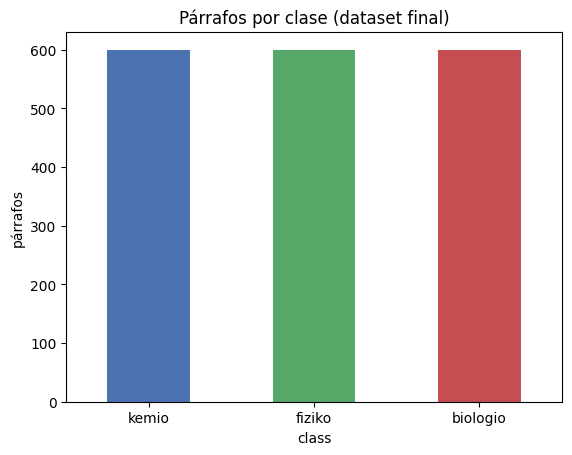

In [5]:
df_final = equilibrar(df_completo, MAX_PARRAFOS_POR_CLASE)

# Comprobación del contrato de datos
assert not df_final["text"].str.contains(";").any(), "Hay párrafos con ';'"
assert set(df_final.columns) >= {"text", "class"}

df_final[["text", "class"]].to_csv(ARCHIVO_DATASET, sep=";", index=False, encoding="utf-8")
df_final[["text", "class", "article"]].to_csv(ARCHIVO_DATASET_ARTICULOS, sep=";", index=False, encoding="utf-8")

releido = pd.read_csv(ARCHIVO_DATASET, sep=";", encoding="utf-8")
assert list(releido.columns) == ["text", "class"] and len(releido) == len(df_final)
print(f"Guardado {ARCHIVO_DATASET}: {len(releido)} párrafos ({releido['class'].value_counts().min()} por clase)")

if releido["class"].value_counts().min() < 300:
    print("AVISO: alguna clase tiene menos de 300 párrafos (el enunciado recomienda más). "
          "Sube MAX_ARTICULOS_POR_CLASE o añade categorías en CATEGORIAS.")

ax = df_final["class"].value_counts().plot(kind="bar", color=["#4c72b0", "#55a868", "#c44e52"], rot=0)
ax.set_title("Párrafos por clase (dataset final)")
ax.set_ylabel("párrafos")
plt.show()

## 3. Fase 2 — Modelo de NLP para Esperanto

Construimos desde cero (sin spaCy, NLTK ni Stanza) un modelo **basado en reglas** con una API parecida a la de spaCy:

```python
nlp = Esperanto()
doc = nlp("La juna instruistino legas interesan libron.")
for token in doc:
    print(token.text, token.lemma_, token.pos_, token.is_stop)
```

### 3.1 Reglas gramaticales que usamos
El Esperanto es regular: **la terminación de una palabra dice su categoría**.

| Terminación | Categoría | Ejemplo → lema |
|---|---|---|
| `-o` | sustantivo (NOUN) | `libroj` → `libro` |
| `-a` | adjetivo (ADJ) | `bonajn` → `bona` |
| `-e` | adverbio (ADV) | `rapide` → `rapide` |
| `-i`, `-as`, `-is`, `-os`, `-us`, `-u` | verbo (VERB) | `kantis` → `kanti` |

* Sustantivos y adjetivos pueden llevar **`-j`** (plural) y **`-n`** (acusativo), siempre en ese orden: `libr-o-j-n`.
* Todos los verbos se lematizan al **infinitivo** (`-i`): `legas`, `legis`, `legos` → `legi`.
* Los **correlativos** (`kiu`, `tio`, `ĉiam`...) se generan con una rejilla: prefijo (`ki-`, `ti-`, `i-`, `ĉi-`, `neni-`) + terminación (`-o`, `-u`, `-a`, `-es`, `-e`, `-am`, `-al`, `-el`, `-om`).
* Los **pronombres** y **posesivos** son un conjunto cerrado (`mi`, `min`, `mia`, `miajn`...).
* Palabras de **clase cerrada** (artículo `la`, preposiciones, conjunciones, partículas) se listan a mano: si no, su final
  se confundiría con una terminación (`ĝis` parecería un verbo en `-is`, `pro` un sustantivo en `-o`).
* **Nombres propios (PROPN):** palabra con mayúscula que no abre frase, o con mayúscula y sin terminación esperantista.

**Límites que asumimos:** no analizamos participios (`-ant-`, `-it-`...) ni separamos afijos (`mal-`, `-ist-`...); el lema es raíz + terminación.
Los participios no se pueden detectar solo por la terminación sin confundirlos con raíces normales (`planto`, `ŝtato`).
Los nombres extranjeros que acaban en `-o`, `-a` o `-n` se pueden lematizar mal (`Princeton` → `princeto`), aunque se etiquetan como `PROPN`.

In [6]:
# ---- 3.2 Recursos: listas cerradas y stop-words ----
URL_STOPWORDS = "https://raw.githubusercontent.com/jparisu/nlp-esperantilo/main/resources/esperanto/vortoj.json"

ARTICULO = {"la"}
PRONOMBRES = {"mi", "vi", "li", "ŝi", "ĝi", "ni", "ili", "oni", "si", "ci"}
PREPOSICIONES = {"al", "anstataŭ", "antaŭ", "apud", "ĉe", "ĉirkaŭ", "da", "de", "dum", "ekde", "ekster", "el", "en", "ĝis",
                 "inter", "je", "kontraŭ", "krom", "kun", "laŭ", "malantaŭ", "malgraŭ", "per", "po", "por", "post", "preter",
                 "pri", "pro", "sen", "sub", "super", "sur", "tra", "trans"}
CONJ_COORDINANTES = {"kaj", "aŭ", "sed", "nek", "do", "tamen"}
CONJ_SUBORDINANTES = {"ke", "ĉar", "se", "ol", "kvankam", "kvazaŭ"}
ADVERBIOS = {"tre", "tro", "pli", "plej", "plu", "jam", "ankoraŭ", "ankaŭ", "nun", "tuj", "hodiaŭ", "hieraŭ", "morgaŭ",
             "for", "apenaŭ", "baldaŭ", "preskaŭ", "eĉ", "ĉi", "almenaŭ", "mem"}
PARTICULAS = {"ne", "ĉu", "ja", "jen", "ajn", "ju", "des"}
INTERJECCIONES = {"jes", "ha", "he", "ho", "hu", "nu", "ve", "adiaŭ"}
NUMERALES_SIMBOLO = {"plus", "minus"}
RAICES_NUMERALES = "nul|unu|du|tri|kvar|kvin|ses|sep|ok|naŭ|dek|cent|mil"

# palabra -> (categoría, lema)
CERRADAS = {}
for _palabras, _pos in [(ARTICULO, "DET"), (PRONOMBRES, "PRON"), (PREPOSICIONES, "ADP"), (CONJ_COORDINANTES, "CCONJ"),
                        (CONJ_SUBORDINANTES, "SCONJ"), (ADVERBIOS, "ADV"), (PARTICULAS, "PART"),
                        (INTERJECCIONES, "INTJ"), (NUMERALES_SIMBOLO, "NUM")]:
    for _p in _palabras:
        CERRADAS[_p] = (_pos, _p)

# Correlativos: prefijo + terminación (+ flexión permitida). -o admite -n; -u y -a admiten -j y -n; -e admite -n.
PREFIJOS_CORRELATIVOS = ["ki", "ti", "i", "ĉi", "neni"]
TERMINACIONES_CORRELATIVOS = {"o": ("PRON", ["", "n"]), "u": ("DET", ["", "j", "n", "jn"]), "a": ("DET", ["", "j", "n", "jn"]),
                              "es": ("DET", [""]), "e": ("ADV", ["", "n"]), "am": ("ADV", [""]), "al": ("ADV", [""]),
                              "el": ("ADV", [""]), "om": ("ADV", [""])}
CORRELATIVOS = {}      # forma -> (categoría, lema, flexión)
for _pre in PREFIJOS_CORRELATIVOS:
    for _term, (_pos, _flexiones) in TERMINACIONES_CORRELATIVOS.items():
        for _flex in _flexiones:
            CORRELATIVOS[_pre + _term + _flex] = (_pos, _pre + _term, _flex)

# Expresiones regulares (todas se aplican con fullmatch)
RE_NUMERO = re.compile(r"\d+(?:[.,]\d+)*")
RE_NUMERAL = re.compile(f"(?:{RAICES_NUMERALES})+")
RE_PRONOMBRE_ACUSATIVO = re.compile(r"(mi|vi|li|ŝi|ĝi|ni|ili|oni|si|ci)(n)")
RE_POSESIVO = re.compile(r"(mi|vi|li|ŝi|ĝi|ni|ili|oni|si)(a)(j?)(n?)")
RE_SUST_ADJ = re.compile(r"(.+?)([oa])(j?)(n?)")      # raíz + o/a + (j) + (n)
RE_ADVERBIO = re.compile(r"(.+?)(e)(n?)")             # raíz + e + (n)
RE_VERBO = re.compile(r"(.+?)(as|is|os|us|u|i)")      # raíz + terminación verbal
TIEMPOS = {"as": {"Tense": "Pres", "VerbForm": "Fin"}, "is": {"Tense": "Past", "VerbForm": "Fin"},
           "os": {"Tense": "Fut", "VerbForm": "Fin"}, "us": {"Mood": "Cnd", "VerbForm": "Fin"},
           "u": {"Mood": "Imp", "VerbForm": "Fin"}, "i": {"VerbForm": "Inf"}}


def cargar_stopwords():
    """Stop-words del repositorio guía (vortoj.json: las marcadas 'ignorinda'). Plan B: lista mínima propia."""
    try:
        respuesta = requests.get(URL_STOPWORDS, timeout=20)
        respuesta.raise_for_status()
        palabras = {p["vorto"].lower() for p in respuesta.json()["vortoj"] if p.get("ignorinda")}
        return palabras, f"vortoj.json de GitHub ({len(palabras)} palabras)"
    except (requests.RequestException, ValueError, KeyError):
        respaldo = set(CERRADAS) | {"esti", "havi", "povi", "devi", "voli"} | set(RAICES_NUMERALES.split("|"))
        return respaldo, f"lista de respaldo del cuaderno ({len(respaldo)} palabras)"


STOPWORDS, ORIGEN_STOPWORDS = cargar_stopwords()
print("Stop-words cargadas desde:", ORIGEN_STOPWORDS)

Stop-words cargadas desde: vortoj.json de GitHub (122 palabras)


In [7]:
# ---- 3.3 Tokenizador ----
# Una palabra son letras (incluidas ĉ ĝ ĥ ĵ ŝ ŭ), con guiones o apóstrofos dentro; un número admite . o , dentro;
# cualquier otro símbolo es un token de puntuación.
PATRON_TOKEN = re.compile(r"[^\W\d_]+(?:[-’'][^\W\d_]+)*|\d+(?:[.,]\d+)*|[^\w\s]")


def normalizar(texto):
    """Unicode NFC: así 'ĉ' siempre es una sola letra, y no 'c' + una marca combinante."""
    return unicodedata.normalize("NFC", texto)


def tokenizar(texto):
    return PATRON_TOKEN.findall(normalizar(texto))

In [8]:
# ---- 3.4 Etiquetado morfológico (POS) y lematización ----

def analizar_palabra(palabra, inicio_de_frase=False):
    """Devuelve (categoría, lema, morfología) de un token, solo con reglas. Se prueba en orden:
    número -> sigla -> clase cerrada -> correlativo -> pronombre/posesivo -> numeral -> terminaciones -> desconocida."""
    bajo = palabra.lower()

    if RE_NUMERO.fullmatch(palabra):
        return "NUM", palabra, {}
    if not any(c.isalpha() for c in palabra):
        return "PUNCT", palabra, {}
    if len(palabra) > 1 and palabra.isupper():            # DNA, NASA...
        return "X", bajo, {}

    if bajo in CERRADAS:
        return CERRADAS[bajo][0], CERRADAS[bajo][1], {}
    if bajo in CORRELATIVOS:
        pos, lema, flexion = CORRELATIVOS[bajo]
        if pos == "ADV":
            return pos, lema, ({"Case": "Acc"} if flexion else {})
        return pos, lema, _morfologia_nominal(flexion)

    m = RE_PRONOMBRE_ACUSATIVO.fullmatch(bajo)            # min, vin, lin...
    if m:
        return "PRON", m.group(1), {"Case": "Acc"}
    m = RE_POSESIVO.fullmatch(bajo)                       # mia, miaj, miajn...
    if m:
        return "DET", m.group(1) + "a", _morfologia_nominal(m.group(3) + m.group(4))
    if RE_NUMERAL.fullmatch(bajo):                        # du, tri, dudek, cent...
        return "NUM", bajo, {}

    pos = lema = None
    morfologia = {}
    m = RE_SUST_ADJ.fullmatch(bajo)
    if m:
        pos = "NOUN" if m.group(2) == "o" else "ADJ"
        lema = m.group(1) + m.group(2)
        morfologia = _morfologia_nominal(m.group(3) + m.group(4))
    else:
        m = RE_ADVERBIO.fullmatch(bajo)
        if m:
            pos, lema = "ADV", m.group(1) + "e"
            morfologia = {"Case": "Acc"} if m.group(3) else {}
        else:
            m = RE_VERBO.fullmatch(bajo)
            if m:
                pos, lema, morfologia = "VERB", m.group(1) + "i", dict(TIEMPOS[m.group(2)])
                if lema == "esti":
                    pos = "AUX"

    if pos is None:                                       # no encaja con ninguna terminación
        return ("PROPN" if palabra[0].isupper() else "X"), bajo, {}
    if palabra[0].isupper() and not inicio_de_frase and pos in {"NOUN", "ADJ", "VERB", "ADV"}:
        pos = "PROPN"                                     # mayúscula en medio de la frase: nombre propio
    return pos, lema, morfologia


def _morfologia_nominal(flexion):
    """Número y caso a partir de las letras 'j' y 'n' finales."""
    morfologia = {"Number": "Plur" if "j" in flexion else "Sing", "Case": "Acc" if "n" in flexion else "Nom"}
    return morfologia

In [9]:
# ---- 3.5 API tipo spaCy: Token, Doc y Esperanto ----
class Token:
    """Una palabra o signo del texto, con sus atributos lingüísticos (como el Token de spaCy)."""

    def __init__(self, text, i, pos_, lemma_, morph, is_stop):
        self.text = text          # texto original
        self.i = i                # posición en el Doc
        self.pos_ = pos_          # categoría gramatical
        self.lemma_ = lemma_      # forma base
        self.morph = morph        # rasgos: número, caso, tiempo...
        self.is_stop = is_stop    # ¿es stop-word?

    @property
    def is_alpha(self):
        return re.sub(r"[-’']", "", self.text).isalpha()

    @property
    def is_punct(self):
        return self.pos_ == "PUNCT"

    @property
    def like_num(self):
        return self.pos_ == "NUM"

    def __repr__(self):
        return self.text


class Doc:
    """Resultado de procesar un texto: una secuencia de Token."""

    def __init__(self, text, tokens):
        self.text = text
        self.tokens = tokens

    def __len__(self):
        return len(self.tokens)

    def __iter__(self):
        return iter(self.tokens)

    def __getitem__(self, indice):
        return self.tokens[indice]

    def __repr__(self):
        return self.text

    @property
    def sents(self):
        """Frases (listas de tokens), cortando en . ! ? y …"""
        frases, actual = [], []
        for token in self.tokens:
            actual.append(token)
            if token.text in {".", "!", "?", "…"}:
                frases.append(actual)
                actual = []
        if actual:
            frases.append(actual)
        return frases

    def to_table(self):
        """Tabla con un token por fila, para verla en el cuaderno."""
        return pd.DataFrame({"text": [t.text for t in self], "lemma_": [t.lemma_ for t in self],
                             "pos_": [t.pos_ for t in self], "is_stop": [t.is_stop for t in self],
                             "morph": [" ".join(f"{k}={v}" for k, v in t.morph.items()) for t in self]})


CATEGORIAS_FUNCIONALES = {"DET", "ADP", "CCONJ", "SCONJ", "PRON", "PART", "INTJ"}


class Esperanto:
    """Modelo de NLP para Esperanto basado en reglas. Uso: nlp = Esperanto(); doc = nlp("texto")."""

    def __init__(self, stopwords=None):
        self.stopwords = STOPWORDS if stopwords is None else stopwords

    def __call__(self, texto):
        palabras = tokenizar(texto)
        tokens = []
        for i, palabra in enumerate(palabras):
            inicio_de_frase = (i == 0) or palabras[i - 1] in {".", "!", "?", "…"}
            pos, lema, morfologia = analizar_palabra(palabra, inicio_de_frase)
            # stop-word: palabra funcional (artículo, preposición, pronombre...), correlativo (los 45 lo son),
            # palabra de las listas cerradas, o presente en la lista de stop-words
            bajo = palabra.lower()
            es_stop = (pos in CATEGORIAS_FUNCIONALES or bajo in CORRELATIVOS or bajo in CERRADAS
                       or lema in self.stopwords or bajo in self.stopwords)
            tokens.append(Token(palabra, i, pos, lema, morfologia, es_stop))
        return Doc(texto, tokens)

    def pipe(self, textos):
        for texto in textos:
            yield self(texto)


nlp = Esperanto()

### 3.6 Pruebas del modelo
Frases de la guía de gramática con el resultado esperado (si algo falla, salta un `AssertionError`), y una tabla de ejemplo.

In [10]:
def lemas(texto):
    return [t.lemma_ for t in nlp(texto) if not t.is_punct]


def categorias(texto):
    return [t.pos_ for t in nlp(texto) if not t.is_punct]


# Tokenizador
assert tokenizar("La juna instruistino legas interesan libron.") == ["La", "juna", "instruistino", "legas", "interesan", "libron", "."]
assert tokenizar("Ĉu vi legis 3,14 libroj?") == ["Ĉu", "vi", "legis", "3,14", "libroj", "?"]
assert tokenizar("Sud-Afriko estas granda.") == ["Sud-Afriko", "estas", "granda", "."]
assert tokenizar("ĉielo")[0] == "ĉielo"            # 'c' + marca combinante -> 'ĉ' (NFC)

# Lematizador y POS: frase de la guía
assert lemas("La juna instruistino legas interesan libron.") == ["la", "juna", "instruistino", "legi", "interesa", "libro"]
assert categorias("La juna instruistino legas interesan libron.") == ["DET", "ADJ", "NOUN", "VERB", "ADJ", "NOUN"]
assert lemas("Ĉiuj miaj amikoj legas tiujn librojn.") == ["ĉiu", "mia", "amiko", "legi", "tiu", "libro"]

# Verbos, pronombres, adverbios y preposiciones
assert lemas("Mi kantis en la ĝardeno.") == ["mi", "kanti", "en", "la", "ĝardeno"]
assert categorias("Mi kantis en la ĝardeno.") == ["PRON", "VERB", "ADP", "DET", "NOUN"]
assert lemas("Li vidis min.") == ["li", "vidi", "mi"]
assert lemas("Ŝi rapide kuras hejmen.") == ["ŝi", "rapide", "kuri", "hejme"]
assert categorias("Ŝi rapide kuras hejmen.") == ["PRON", "ADV", "VERB", "ADV"]
assert lemas("Ili iros ĝis la urbo.") == ["ili", "iri", "ĝis", "la", "urbo"]   # 'ĝis' no es un verbo en -is

# Números, nombres propios y siglas
assert categorias("En 1950 ili havis dudek tri kemiajn elementojn.") == ["ADP", "NUM", "PRON", "VERB", "NUM", "NUM", "ADJ", "NOUN"]
assert categorias("La fizikisto Albert Einstein naskiĝis en Ulm.") == ["DET", "NOUN", "PROPN", "PROPN", "VERB", "ADP", "PROPN"]
assert lemas("Ĉu vi parolas Esperanton?") == ["ĉu", "vi", "paroli", "esperanto"]
assert categorias("Ĉu vi parolas Esperanton?") == ["PART", "PRON", "VERB", "PROPN"]
assert categorias("La DNA estas molekulo.") == ["DET", "X", "AUX", "NOUN"]

# Stop-words
frase = nlp("La kato estas bela.")
assert [t.is_stop for t in frase if not t.is_punct] == [True, False, True, False]
assert all(nlp(c)[0].is_stop for c in ["kiam", "tiujn", "ĉie", "nenio", "miajn", "ĝis"])   # correlativos y funcionales

# Morfología
assert nlp("librojn")[0].morph == {"Number": "Plur", "Case": "Acc"}
assert nlp("kantos")[0].morph == {"Tense": "Fut", "VerbForm": "Fin"}

print("Todas las pruebas del modelo pasan.")
nlp("La juna instruistino legas interesan libron. Ĉiuj miaj amikoj legas tiujn librojn.").to_table()

Todas las pruebas del modelo pasan.


,text,lemma_,pos_,is_stop,morph
0,La,la,DET,True,
1,juna,juna,ADJ,False,Number=Sing Case=Nom
2,instruistino,instruistino,NOUN,False,Number=Sing Case=Nom
3,legas,legi,VERB,False,Tense=Pres VerbForm=Fin
4,interesan,interesa,ADJ,False,Number=Sing Case=Acc
5,libron,libro,NOUN,False,Number=Sing Case=Acc
6,.,.,PUNCT,False,
7,Ĉiuj,ĉiu,DET,True,Number=Plur Case=Nom
8,miaj,mia,DET,True,Number=Plur Case=Nom
9,amikoj,amiko,NOUN,False,Number=Plur Case=Nom


## 4. Primer análisis del corpus con nuestro modelo
Aplicamos el modelo de la Fase 2 al dataset de la Fase 1 para comprobar que ambos encajan y para ver cómo es el corpus.
Esto también nos sirve de **diagnóstico del etiquetador**: el porcentaje de tokens `X` (palabras que no reconoce) indica cuánto falla.

In [11]:
inicio = time.time()
docs = [nlp(texto) for texto in df_final["text"]]
print(f"{len(docs)} párrafos procesados en {time.time() - inicio:.1f} s")

df_final["n_tokens"] = [len(d) for d in docs]
df_final["n_contenido"] = [sum(1 for t in d if t.pos_ in {"NOUN", "ADJ", "VERB"} and not t.is_stop) for d in docs]

resumen = []
for clase in df_final["class"].unique():
    tokens = [t for d, c in zip(docs, df_final["class"]) if c == clase for t in d]
    palabras = [t for t in tokens if not t.is_punct]
    resumen.append({
        "clase": clase,
        "tokens": len(tokens),
        "% stop-words": round(100 * sum(t.is_stop for t in palabras) / len(palabras), 1),
        "% nombres propios": round(100 * sum(t.pos_ == "PROPN" for t in palabras) / len(palabras), 1),
        "% desconocidas (X)": round(100 * sum(t.pos_ == "X" for t in palabras) / len(palabras), 1),
    })
resumen = pd.DataFrame(resumen).set_index("clase")
print(resumen.to_string())

# Ruido medido con el modelo: párrafos con muy pocas palabras de contenido
pocos = df_final.assign(poco_contenido=df_final["n_contenido"] < 8).groupby("class")["poco_contenido"].mean() * 100
print("\n% de párrafos con menos de 8 palabras de contenido (posible ruido):")
print(pocos.round(1).to_string())

1800 párrafos procesados en 0.7 s
          tokens  % stop-words  % nombres propios  % desconocidas (X)
clase                                                                
kemio      36120          42.0                4.5                 1.8
fiziko     36717          44.9                3.7                 1.7
biologio   40223          43.3                4.7                 1.4

% de párrafos con menos de 8 palabras de contenido (posible ruido):
class
biologio    5.2
fiziko      4.2
kemio       5.7


         biologio         fiziko           kemio
0    specio (119)  energio (127)  elemento (150)
1    planto (106)     forto (99)    izotopo (95)
2       homo (63)    teorio (94)     metalo (74)
3       nomo (63)     korpo (85)      likvo (73)
4      parto (61)  partiklo (73)      stato (72)
5       ĉelo (58)      leĝo (70)       akvo (72)
6  organismo (58)   sistemo (67)      atomo (66)
7    malsano (48)    fiziko (65)       fero (63)
8       akvo (47)   objekto (64)      stano (58)
9       geno (46)      sono (63)   molekulo (54)


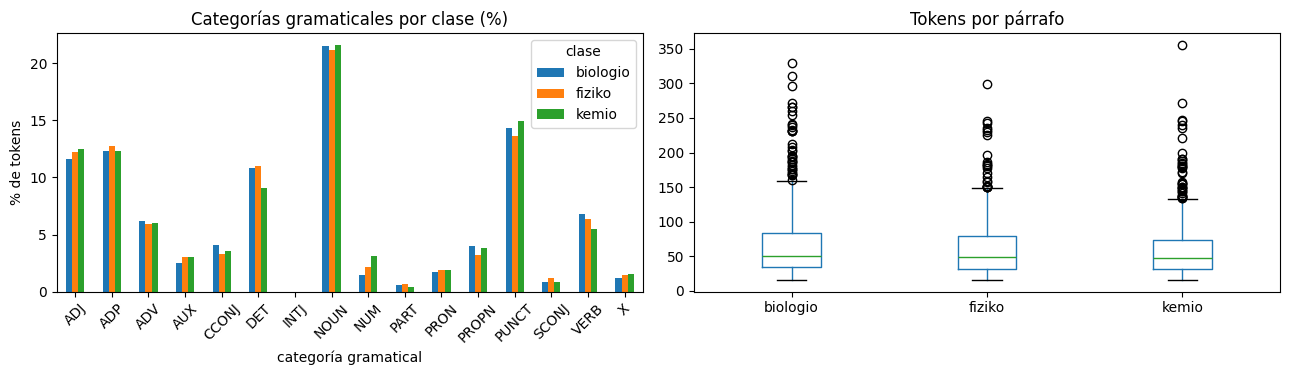

In [13]:
# Sustantivos más frecuentes de cada clase (sin stop-words) y reparto de categorías gramaticales
fig, ejes = plt.subplots(1, 2, figsize=(13, 4))

top = {}
for clase in sorted(df_final["class"].unique()):
    lemas_clase = Counter(t.lemma_ for d, c in zip(docs, df_final["class"]) if c == clase
                          for t in d if t.pos_ == "NOUN" and not t.is_stop)
    top[clase] = [f"{lema} ({n})" for lema, n in lemas_clase.most_common(10)]
print(pd.DataFrame(top).to_string())

reparto = pd.crosstab(pd.Series([t.pos_ for d in docs for t in d], name="categoría gramatical"),
                      pd.Series([c for d, c in zip(docs, df_final["class"]) for _ in d], name="clase"),
                      normalize="columns") * 100
reparto.plot(kind="bar", ax=ejes[0], rot=45)
ejes[0].set_title("Categorías gramaticales por clase (%)")
ejes[0].set_ylabel("% de tokens")

df_final.boxplot(column="n_tokens", by="class", ax=ejes[1], grid=False)
ejes[1].set_title("Tokens por párrafo")
ejes[1].set_xlabel("")
plt.suptitle("")
plt.tight_layout()
plt.show()

## 5. Pendiente para la entrega final (Fase 3)
* **Vectorización**: bolsa de palabras / TF-IDF sobre los lemas, filtrando por categoría gramatical (sin `PROPN` ni stop-words) y por frecuencia de documento.
* **Partición train/test por artículo** (columna `article`), para evitar que palabras de un mismo artículo estén a la vez en train y en test.
* **Entrenamiento** de un clasificador que dé probabilidades (regresión logística o Naive Bayes), con semilla fija.
* **Evaluación**: accuracy, F1 macro y matriz de confusión, con interpretación de los errores (por ejemplo, química ↔ biología).
* **Clasificación de una página web real** en Esperanto, con probabilidad por categoría y control de errores de red.
* Mejoras del modelo de NLP: participios, afijos y evaluación de la tasa de palabras desconocidas.